# AlphaDev sorting-network base cases — тестовый прогон

Один прогон авторского кода `bazel-bin/benchmark` (Google Benchmark 1.5.0, clang 18.1.3, Bazel 7.4.1, `-c opt`), на одном ядре через `taskset -c 0`.

**Моя машина:** Intel Core i9-12900H (desktop, WSL2). **Их машина:** AMD Ryzen 5 1600AF (desktop, WSL).

Тут задача была воспроизвести код и показать, что он исполняется, графики я тоже нарисовала для красоты, но они довольно шумные.

Сюда записали результаты после прогона авторской репошки (которую еще пришлось чинить, но это другая история)

In [ ]:
import glob, sys
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print(sys.executable)

csv_path = sorted(glob.glob('benchmark_*.csv'))[-1]
print('Using', csv_path)

with open(csv_path) as f:
    lines = f.read().splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith('name,'))
df = pd.read_csv(StringIO('\n'.join(lines[start:])))

parts = df['name'].str.extract(r'^BM_(?P<algo>.+)_(?P<input>Random|Sorted|NearlySorted)/(?P<n>\d+)')
df = pd.concat([df, parts], axis=1)
df['n'] = df['n'].astype(int)
df['family'] = df['algo'].str.extract(r'^(MergeSort|QuickSort)')[0]
df['variant'] = df['algo'].str.replace(r'^(MergeSort|QuickSort)', '', regex=True)
df['ns_per_elem'] = df['real_time'] / df['n']
print(f"{len(df)} benchmarks, {df['algo'].nunique()} algorithms, N from {df['n'].min()} to {df['n'].max()}")
df.head()

/home/zlovoblachko/miniconda3/envs/coherence_proj/bin/python
Using benchmark_20261024_050526.csv
726 benchmarks, 22 algorithms, N from 1024 to 1048576


,name,iterations,real_time,cpu_time,time_unit,bytes_per_second,items_per_second,label,error_occurred,error_message,algo,input,n,family,variant,ns_per_elem
0,BM_MergeSortClassic_Random/1024/real_time,8192,82443.2,82427.3,ns,NaN,NaN,NaN,NaN,NaN,MergeSortClassic,Random,1024,MergeSort,Classic,80.510937
1,BM_MergeSortClassic_Random/2048/real_time,4286,165403.0,165376.0,ns,NaN,NaN,NaN,NaN,NaN,MergeSortClassic,Random,2048,MergeSort,Classic,80.763184
2,BM_MergeSortClassic_Random/4096/real_time,2034,344606.0,344593.0,ns,NaN,NaN,NaN,NaN,NaN,MergeSortClassic,Random,4096,MergeSort,Classic,84.132324
3,BM_MergeSortClassic_Random/8192/real_time,980,770968.0,770966.0,ns,NaN,NaN,NaN,NaN,NaN,MergeSortClassic,Random,8192,MergeSort,Classic,94.112305
4,BM_MergeSortClassic_Random/16384/real_time,408,1677200.0,1649760.0,ns,NaN,NaN,NaN,NaN,NaN,MergeSortClassic,Random,16384,MergeSort,Classic,102.368164


## Время vs. объем массива
Ванильный вариант нарисован черной линией

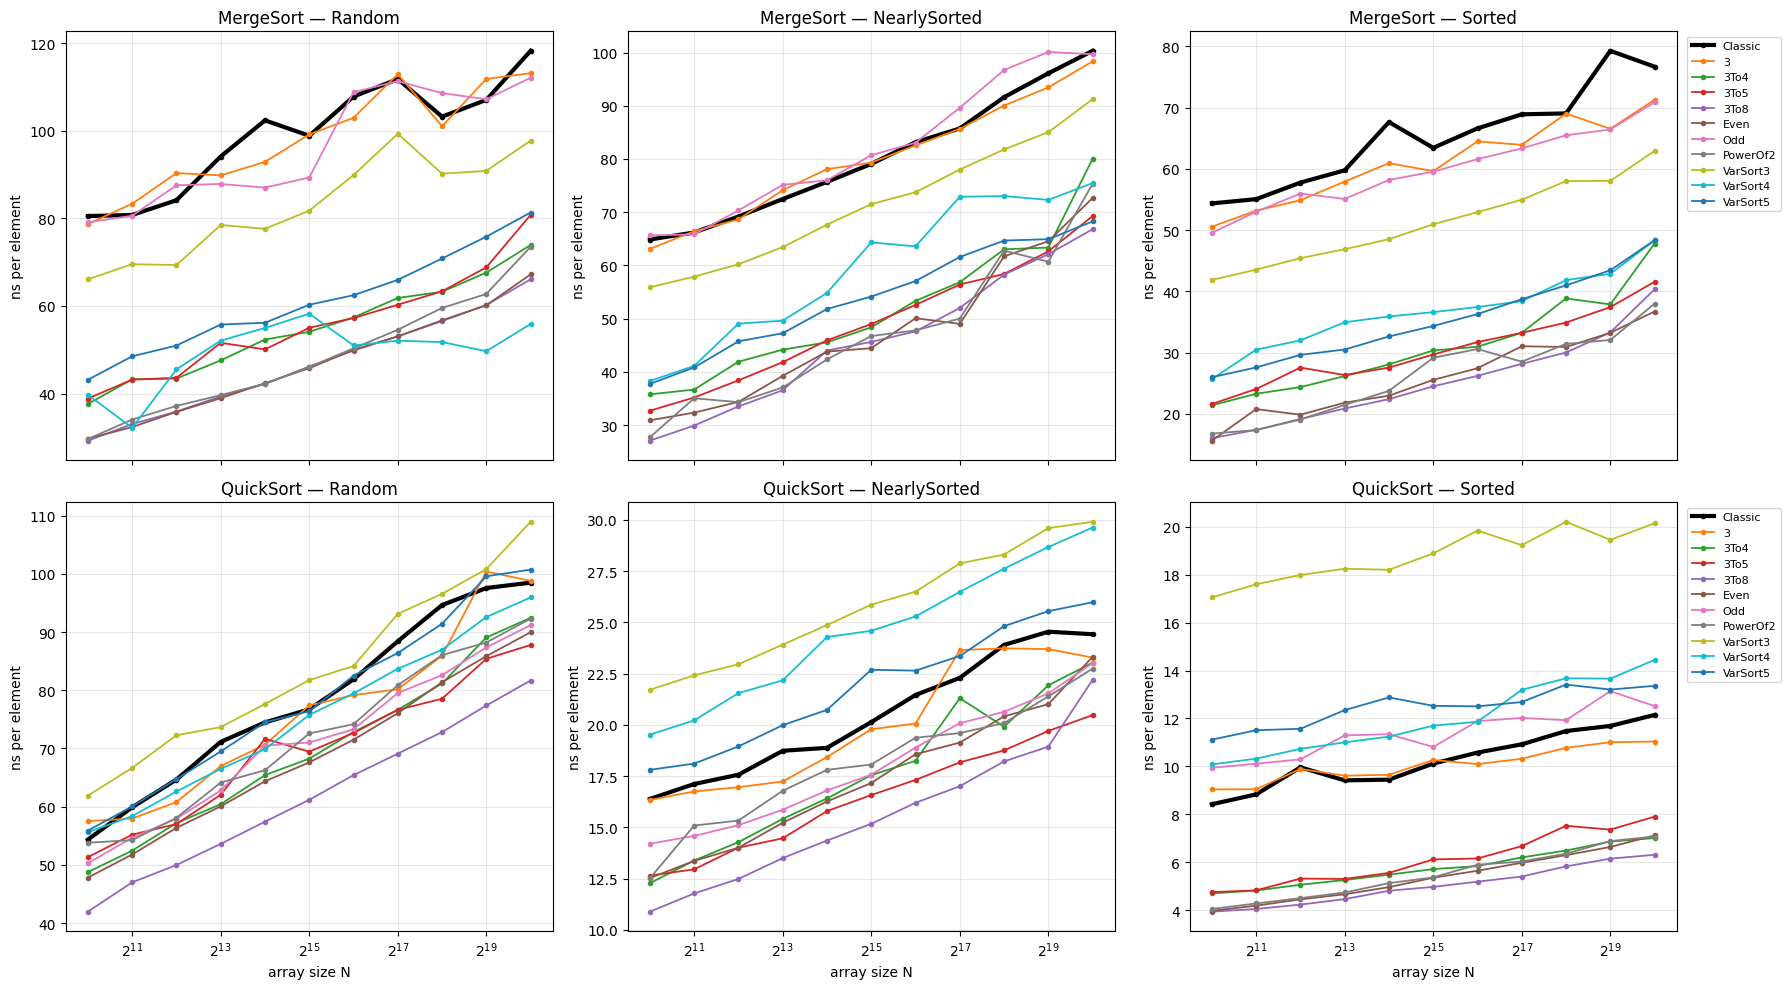

In [2]:
inputs = ['Random', 'NearlySorted', 'Sorted']
families = ['MergeSort', 'QuickSort']
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True)
cmap = plt.get_cmap('tab10')
for r, fam in enumerate(families):
    for c, inp in enumerate(inputs):
        ax = axes[r, c]
        sub = df[(df.family == fam) & (df.input == inp)]
        others = [v for v in sorted(sub.variant.unique()) if v != 'Classic']
        for i, v in enumerate(['Classic'] + others):
            s = sub[sub.variant == v].sort_values('n')
            style = dict(color='black', lw=3) if v == 'Classic' else dict(color=cmap(i % 10), lw=1.3)
            ax.plot(s.n, s.ns_per_elem, marker='o', ms=3, label=v, **style)
        ax.set_xscale('log', base=2)
        ax.set_title(f'{fam} — {inp}')
        ax.set_ylabel('ns per element')
        ax.grid(alpha=.3)
for ax in axes[1]:
    ax.set_xlabel('array size N')
for ax in axes[:, 2]:
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## Ускорение на классике

По авторской метрике считаем ускорение как классика / вариант, и хотим видеть результат больше 1, усреднили по размерам геометрическим средним.

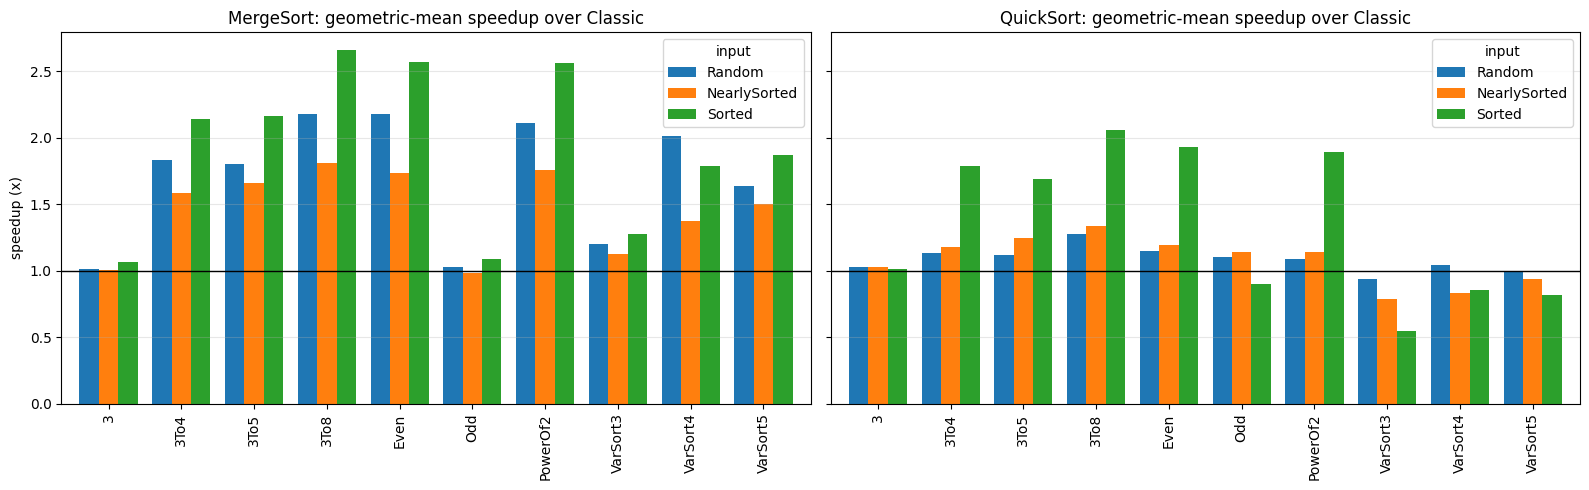

input               Random  NearlySorted  Sorted
family    variant                               
MergeSort 3           1.01          1.00    1.07
          3To4        1.83          1.58    2.14
          3To5        1.80          1.66    2.16
          3To8        2.18          1.81    2.66
          Even        2.18          1.74    2.57
          Odd         1.03          0.98    1.09
          PowerOf2    2.11          1.75    2.56
          VarSort3    1.20          1.13    1.27
          VarSort4    2.01          1.37    1.79
          VarSort5    1.64          1.50    1.87
QuickSort 3           1.03          1.03    1.02
          3To4        1.13          1.18    1.79
          3To5        1.12          1.25    1.69
          3To8        1.28          1.34    2.05
          Even        1.15          1.19    1.93
          Odd         1.10          1.14    0.90
          PowerOf2    1.09          1.14    1.89
          VarSort3    0.94          0.79    0.54
          VarSort4    1.04          0.83    0.86
          VarSort5    1.00          0.94    0.82

In [3]:
base = df[df.variant == 'Classic'].set_index(['family', 'input', 'n'])['real_time']
d = df[df.variant != 'Classic'].copy()
d['speedup'] = base.loc[list(zip(d.family, d.input, d.n))].values / d.real_time.values
gm = d.groupby(['family', 'variant', 'input'])['speedup'].apply(lambda x: np.exp(np.log(x).mean())).unstack('input')[inputs]

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, fam in zip(axes, families):
    gm.loc[fam].plot.bar(ax=ax, width=.8)
    ax.axhline(1, color='black', lw=1)
    ax.set_title(f'{fam}: geometric-mean speedup over Classic')
    ax.set_xlabel(''); ax.set_ylabel('speedup (x)')
    ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()
gm.round(2)

## Ускорение для наибольшего размера

In [4]:
big = d[d.n == d.n.max()].pivot_table(index=['family', 'variant'], columns='input', values='speedup')[inputs]
big.round(2)

input               Random  NearlySorted  Sorted
family    variant                               
MergeSort 3           1.05          1.02    1.08
          3To4        1.60          1.25    1.60
          3To5        1.46          1.45    1.85
          3To8        1.79          1.50    1.90
          Even        1.76          1.38    2.09
          Odd         1.05          1.01    1.08
          PowerOf2    1.61          1.33    2.02
          VarSort3    1.21          1.10    1.22
          VarSort4    2.12          1.33    1.59
          VarSort5    1.45          1.47    1.59
QuickSort 3           1.00          1.05    1.10
          3To4        1.07          1.06    1.73
          3To5        1.12          1.19    1.54
          3To8        1.21          1.10    1.93
          Even        1.09          1.05    1.71
          Odd         1.08          1.06    0.97
          PowerOf2    1.07          1.07    1.72
          VarSort3    0.90          0.82    0.60
          VarSort4    1.03          0.82    0.84
          VarSort5    0.98          0.94    0.91

## Версия кода для алгоритмов 1 и 2 на питоне

По времени, конечно, ничего сказать не сможем, потому что питон это не плюсы, но как бы работает

In [ ]:
import random
import time

# пойдем по кустарному пути и определим сети сортировки для массивов размером 3–8 вручную
SORTING_NETWORKS = {
    3: [(0, 2), (0, 1), (1, 2)],
    4: [(0, 2), (1, 3), (0, 1), (2, 3), (1, 2)],
    5: [(0, 3), (1, 4), (0, 2), (1, 3), (0, 1), (2, 4), (1, 2), (3, 4), (2, 3)],
    6: [(0, 5), (1, 3), (2, 4), (1, 2), (3, 4), (0, 3), (2, 5), (0, 1),
        (2, 3), (4, 5), (1, 2), (3, 4)],
    7: [(0, 6), (2, 3), (4, 5), (0, 2), (1, 4), (3, 6), (0, 1), (2, 5),
        (3, 4), (1, 2), (4, 6), (2, 3), (4, 5), (1, 2), (3, 4), (5, 6)],
    8: [(0, 2), (1, 3), (4, 6), (5, 7), (0, 4), (1, 5), (2, 6), (3, 7),
        (0, 1), (2, 3), (4, 5), (6, 7), (2, 4), (3, 5), (1, 4), (3, 6),
        (1, 2), (3, 4), (5, 6)],
}

# конфигурации, которые мы будем тестировать
CONFIGURATIONS = {
    "Classic": set(),
    "PowerOf2": {4, 8},
    "Even": {4, 6, 8},
    "Odd": {3, 5, 7},
    "3": {3},
    "3To4": {3, 4},
    "3To5": {3, 4, 5},
    "3To8": {3, 4, 5, 6, 7, 8},
    "6To8": {6, 7, 8},
}

# функция для применения сети сортировки
def apply_sorting_network(array, left, size):
    for i, j in SORTING_NETWORKS[size]:
        a, b = left + i, left + j
        if array[a] > array[b]:
            array[a], array[b] = array[b], array[a]

# функция слияния для сортировки слиянием
def merge(array, left, mid, right):
    left_part = array[left:mid + 1]
    right_part = array[mid + 1:right + 1]
    i = j = 0
    k = left
    while i < len(left_part) and j < len(right_part):
        if left_part[i] <= right_part[j]:
            array[k] = left_part[i]
            i += 1
        else:
            array[k] = right_part[j]
            j += 1
        k += 1
    while i < len(left_part):
        array[k] = left_part[i]
        i += 1
        k += 1
    while j < len(right_part):
        array[k] = right_part[j]
        j += 1
        k += 1

# оптимизированная версия сортировки слиянием с сетями сортировки
def optimized_merge_sort(array, left, right, network_sizes):
    size = right - left + 1
    if size in network_sizes:
        apply_sorting_network(array, left, size)
        return
    if left < right:
        mid = left + (right - left) // 2
        optimized_merge_sort(array, left, mid, network_sizes)
        optimized_merge_sort(array, mid + 1, right, network_sizes)
        merge(array, left, mid, right)

# функция для выбора медианы для quick sort
def median_of_three(array, low, high):
    mid = low + (high - low) // 2
    if array[mid] < array[low]:
        array[low], array[mid] = array[mid], array[low]
    if array[high] < array[low]:
        array[low], array[high] = array[high], array[low]
    if array[high] < array[mid]:
        array[mid], array[high] = array[high], array[mid]
    return mid

# разбивка Хоара для quick sort
def hoare_partition(array, low, high, pivot_index):
    pivot = array[pivot_index]
    i = low - 1
    j = high + 1
    while True:
        i += 1
        while array[i] < pivot:
            i += 1
        j -= 1
        while array[j] > pivot:
            j -= 1
        if i >= j:
            return j
        array[i], array[j] = array[j], array[i]

# оптимизированная версия быстрой сортировки с сетями сортировки
def optimized_quick_sort(array, low, high, network_sizes):
    size = high - low + 1
    if size in network_sizes:
        apply_sorting_network(array, low, size)
        return
    if low < high:
        pivot_index = median_of_three(array, low, high)
        partition_index = hoare_partition(array, low, high, pivot_index)
        optimized_quick_sort(array, low, partition_index, network_sizes)
        optimized_quick_sort(array, partition_index + 1, high, network_sizes)

# проверка корректности сетей сортировки
def check_networks():
    for size, network in SORTING_NETWORKS.items():
        for mask in range(2 ** size):
            values = [(mask >> bit) & 1 for bit in range(size)]
            apply_sorting_network(values, 0, size)
            assert values == sorted(values), f"network {size} failed"

# проверка корректности алгоритмов сортировки
def check_algorithms(trials=200):
    for _ in range(trials):
        n = random.randint(0, 300)
        data = [random.randint(0, 50) for _ in range(n)]
        for sizes in CONFIGURATIONS.values():
            a = data[:]
            optimized_merge_sort(a, 0, len(a) - 1, sizes)
            assert a == sorted(data)
            b = data[:]
            optimized_quick_sort(b, 0, len(b) - 1, sizes)
            assert b == sorted(data)

# функция для измерения времени сортировки
def time_sort(sort_function, data, network_sizes, repeats=3):
    best = float("inf")
    for _ in range(repeats):
        a = data[:]
        start = time.perf_counter()
        sort_function(a, 0, len(a) - 1, network_sizes)
        best = min(best, time.perf_counter() - start)
    return best * 1000

# функция для генерации входных данных
def make_input(kind, n):
    data = list(range(n))
    if kind == "random":
        random.shuffle(data)
    elif kind == "nearly sorted":
        for _ in range(n // 100):
            i, j = random.randrange(n), random.randrange(n)
            data[i], data[j] = data[j], data[i]
    return data

# основная функция для запуска всего этого дела
def main():
    random.seed(1)
    check_networks()
    check_algorithms()
    print("All networks and both algorithms sort correctly.\n")

    n = 10_000
    shown = ["Classic", "3To5", "3To8", "6To8", "PowerOf2"]
    for kind in ["random", "sorted", "nearly sorted"]:
        data = make_input(kind, n)
        print(f"{kind} input, n = {n}")
        print(f"  {'configuration':<14}{'merge sort (ms)':>17}{'quick sort (ms)':>17}")
        for name in shown:
            sizes = CONFIGURATIONS[name]
            ms = time_sort(optimized_merge_sort, data, sizes)
            qs = time_sort(optimized_quick_sort, data, sizes)
            print(f"  {name:<14}{ms:>17.2f}{qs:>17.2f}")
        print()


if __name__ == "__main__":
    main()

All networks and both algorithms sort correctly.

random input, n = 10000
  configuration   merge sort (ms)  quick sort (ms)
  Classic                   13.83             8.69
  3To5                      11.15             7.04
  3To8                      11.14             6.67


  6To8                      13.92             7.43
  PowerOf2                  13.47             7.98

sorted input, n = 10000
  configuration   merge sort (ms)  quick sort (ms)
  Classic                   10.97             6.15
  3To5                       8.23             4.07
  3To8                       8.30             4.02


  6To8                      10.87             6.17
  PowerOf2                  10.67             5.90

nearly sorted input, n = 10000
  configuration   merge sort (ms)  quick sort (ms)
  Classic                   12.29             6.28
  3To5                       9.29             4.11
  3To8                       9.28             4.05


  6To8                      12.01             6.06
  PowerOf2                  11.61             5.97

